# Reprodução do Wi-Chat — Notebook 03: experimentos extras

Três experimentos curtos, escolhidos por darem muito retorno com pouco esforço:

| | Experimento | Pergunta que responde | Custo |
|---|---|---|---|
| **C** | Métodos treinados melhores (SVM com medidas de variação, CNN, SVM com só 3 exemplos) | Quão perto os LLMs ficam de métodos treinados de verdade? | grátis |
| **A** | Gráficos com **escala vertical fixa**, só para as estratégias com imagem | A imagem piorou por causa da escala automática? | ~R$ 2–5 |
| **B** | **Gemini maior** (Flash) em 3 estratégias, opcional | A dificuldade com imagem é do modelo Lite? | ~R$ 5–15 |

No final, uma **tabela única e um gráfico** com tudo (notebook 02 + extras), prontos para os slides.

**Pré-requisito:** os notebooks 01 e 02 já rodaram. **Ambiente:** CPU basta. A CNN treina em poucos minutos.

## 1. Configuração e dados (os mesmos do notebook 02)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

MATERIA = '/content/drive/MyDrive/Semestres/10 Semestre/Tópicos em Computação'
PROJ    = f'{MATERIA}/wichat_repro'
DATA    = f'{PROJ}/data'
NB02    = f'{PROJ}/nb02'
OUT     = f'{PROJ}/nb03'
IMG_FIX = f'{OUT}/imagens_escala_fixa'
os.makedirs(IMG_FIX, exist_ok=True)

SEED, FS = 42, 320
SG_JANELA, SG_ORDEM, PASSO = 31, 3, 16          # iguais ao notebook 02
LABELS = ['fall', 'no event', 'walk']

z = np.load(f'{DATA}/alsaify_segmentos.npz', allow_pickle=True)
X, ids = z['X'], z['ids']
meta = pd.read_csv(f'{DATA}/alsaify_meta.csv')
S = np.stack([savgol_filter(X[i].astype(np.float32).mean(axis=1), SG_JANELA, SG_ORDEM)[::PASSO] for i in range(len(X))])
meta['std_media'] = S.std(axis=1)
teste  = meta[meta.split == 'test'].reset_index()
treino = meta[meta.split == 'train'].reset_index()

itens02 = [json.loads(l) for l in open(f'{NB02}/prompts_teste.jsonl')]
print('Séries:', S.shape, '| teste:', len(teste), '| treino:', len(treino), '| prompts do nb02:', len(itens02))

Mounted at /content/drive
Séries: (390, 100) | teste: 117 | treino: 273 | prompts do nb02: 819


## 2. Experimento C: métodos treinados melhores (grátis)

O SVM do notebook 02 recebia os 100 valores brutos. Como o nível do sinal muda muito entre pessoas e salas, ele tinha dificuldade em perceber o que importa: **quanto o sinal varia**. Aqui testamos quatro métodos supervisionados:

| Método | Entrada | Treino |
|---|---|---|
| `SVM bruto` | os 100 valores (o mesmo do notebook 02) | 273 janelas |
| `SVM com medidas` | 4 medidas simples de variação: desvio-padrão, amplitude (máx − mín), variação média e máxima entre pontos vizinhos | 273 janelas |
| `CNN 1D` | os 100 valores, centralizados na média | 273 janelas; Adam, taxa 0,001, 30 épocas, lote 32 (como no artigo); média de 5 execuções |
| `SVM com medidas, 3 exemplos` | as mesmas 4 medidas | **só os 3 exemplos que o LLM viu no ICL**. É a comparação justa com o ICL |

As medidas não usam os rótulos nem processamento complexo: são o que as regras do prompt descrevem ("variação grande", "picos").

In [2]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

def wilson(acertos, n, z=1.96):
    p = acertos / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den; m = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - m, c + m

def medidas(s):
    d = np.abs(np.diff(s))
    return [s.std(), s.max() - s.min(), d.mean(), d.max()]

F = np.array([medidas(s) for s in S])
itr, ite = treino['index'].values, teste['index'].values
ytr, yte = treino.label.values, teste.label.values

linhas_base = []
def registra(nome, pred, treino_desc):
    acc = accuracy_score(yte, pred); lo, hi = wilson((yte == pred).sum(), len(yte))
    linhas_base.append(dict(metodo=nome, tipo='supervisionado', treino=treino_desc, n=len(yte), acuracia=round(acc, 3),
                            ic95=f'{lo:.2f}–{hi:.2f}', f1_macro=round(f1_score(yte, pred, labels=LABELS, average='macro'), 3)))

svm = lambda: make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=SEED))
registra('SVM bruto', svm().fit(S[itr], ytr).predict(S[ite]), '273 janelas')
registra('SVM com medidas', svm().fit(F[itr], ytr).predict(F[ite]), '273 janelas')

# os 3 exemplos do ICL (mesma regra do notebook 02: a janela de treino mais típica de cada classe)
icl_idx = []
for c in LABELS:
    tr = treino[treino.label == c]
    icl_idx.append(tr.iloc[(tr.std_media - tr.std_media.median()).abs().argsort().iloc[0]]['index'])
registra('SVM com medidas, 3 exemplos', svm().fit(F[icl_idx], LABELS).predict(F[ite]), '3 janelas (as do ICL)')
print('Exemplos do ICL (devem ser os mesmos do nb02):', meta.loc[icl_idx, 'id'].tolist())
pd.DataFrame(linhas_base)

Exemplos do ICL (devem ser os mesmos do nb02): ['als_0203', 'als_0328', 'als_0045']


,metodo,tipo,treino,n,acuracia,ic95,f1_macro
0,SVM bruto,supervisionado,273 janelas,117,0.658,0.57–0.74,0.665
1,SVM com medidas,supervisionado,273 janelas,117,0.880,0.81–0.93,0.880
2,"SVM com medidas, 3 exemplos",supervisionado,3 janelas (as do ICL),117,0.778,0.69–0.84,0.770


In [3]:
import torch, torch.nn as nn

lab2i = {c: i for i, c in enumerate(LABELS)}
def tensor(idx):
    s = S[idx] - S[idx].mean(axis=1, keepdims=True)          # centraliza: tira o nível de cada janela
    return torch.tensor(s[:, None, :], dtype=torch.float32)

Xtr, Xte = tensor(itr), tensor(ite)
Ytr = torch.tensor([lab2i[c] for c in ytr])

def cnn():
    return nn.Sequential(
        nn.Conv1d(1, 16, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(32, 32, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool1d(1),
        nn.Flatten(), nn.Linear(32, 3))

accs, preds = [], []
for seed in range(5):
    torch.manual_seed(seed)
    m = cnn(); opt = torch.optim.Adam(m.parameters(), lr=1e-3); lossf = nn.CrossEntropyLoss()
    for ep in range(30):
        perm = torch.randperm(len(Xtr))
        for b in range(0, len(perm), 32):
            j = perm[b:b + 32]
            opt.zero_grad(); lossf(m(Xtr[j]), Ytr[j]).backward(); opt.step()
    with torch.no_grad():
        p = np.array(LABELS)[m(Xte).argmax(1).numpy()]
    accs.append(accuracy_score(yte, p)); preds.append(p)
print('CNN 1D, acurácia nas 5 execuções:', np.round(accs, 3), '| média', round(np.mean(accs), 3), '± desvio', round(np.std(accs), 3))
registra('CNN 1D (execução mediana)', preds[int(np.argsort(accs)[2])], '273 janelas')
pd.DataFrame(linhas_base)

CNN 1D, acurácia nas 5 execuções: [0.88  0.889 0.88  0.855 0.855] | média 0.872 ± desvio 0.014


,metodo,tipo,treino,n,acuracia,ic95,f1_macro
0,SVM bruto,supervisionado,273 janelas,117,0.658,0.57–0.74,0.665
1,SVM com medidas,supervisionado,273 janelas,117,0.880,0.81–0.93,0.880
2,"SVM com medidas, 3 exemplos",supervisionado,3 janelas (as do ICL),117,0.778,0.69–0.84,0.770
3,CNN 1D (execução mediana),supervisionado,273 janelas,117,0.880,0.81–0.93,0.879


## 3. Experimento A: gráficos com escala vertical fixa

**A hipótese:** no notebook 02, o modelo quase nunca respondeu "no event" quando via o gráfico. Cada imagem ajustava o eixo vertical sozinha, então um sinal quase parado ficava "esticado" e parecia um movimento grande.

**O teste:** refazer as imagens com **a mesma altura de eixo para todas**, centrada na média de cada janela. A altura é escolhida para que 99% das janelas de treino caibam inteiras. A regra não usa os rótulos. Agora um sinal parado aparece como uma linha quase reta, e uma caminhada ocupa o gráfico.

O texto do prompt é **exatamente o mesmo** do notebook 02: só a imagem muda.

Meia-altura fixa do eixo: ±9.32 em torno da média de cada janela


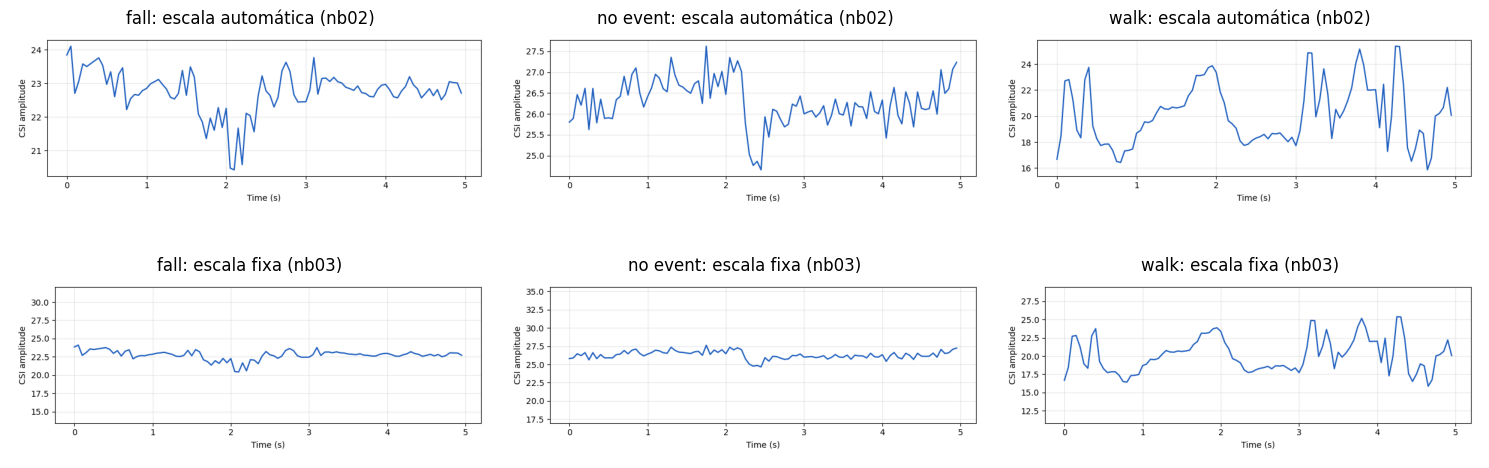

1170 perguntas disponíveis (as 819 do nb02 + 351 com escala fixa)


In [4]:
desvio_max = np.abs(S[itr] - S[itr].mean(axis=1, keepdims=True)).max(axis=1)
R = float(np.percentile(desvio_max, 99))
print(f'Meia-altura fixa do eixo: ±{R:.2f} em torno da média de cada janela')

def salva_fixa(serie, caminho):
    mu = serie.mean()
    fig, ax = plt.subplots(figsize=(8, 3), dpi=100)
    ax.plot(np.arange(len(serie)) * PASSO / FS, serie, color='#1f5fbf', lw=1.6)
    ax.set_ylim(mu - R, mu + R)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('CSI amplitude'); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(caminho); plt.close(fig)

for _, r in teste.iterrows():
    p = f'{IMG_FIX}/{r.id}.png'
    if not os.path.exists(p):
        salva_fixa(S[r['index']], p)

fig, axes = plt.subplots(2, 3, figsize=(15, 5.5))
for j, c in enumerate(LABELS):
    r = teste[teste.label == c].iloc[0]
    axes[0, j].imshow(plt.imread(f'{NB02}/imagens/{r.id}.png')); axes[0, j].set_title(f'{c}: escala automática (nb02)')
    axes[1, j].imshow(plt.imread(f'{IMG_FIX}/{r.id}.png')); axes[1, j].set_title(f'{c}: escala fixa (nb03)')
    for a in axes[:, j]: a.axis('off')
plt.tight_layout(); plt.show()

itens = {}
for it in itens02:
    itens[(it['id'], it['estrategia'])] = dict(it, base_dir=NB02)
    if it['estrategia'].endswith('_img'):
        novo = dict(it, estrategia=it['estrategia'] + '_fix', imagem=f'imagens_escala_fixa/{it["id"]}.png', base_dir=OUT)
        itens[(it['id'], novo['estrategia'])] = novo
print(len(itens), 'perguntas disponíveis (as 819 do nb02 + 351 com escala fixa)')

**O que conferir:** na linha de baixo, o "no event" deve aparecer quase reto, enquanto "walk" e "fall" ainda mostram os picos.

## 4. Conexão com o Gemini

Usa a mesma chave (`GEMINI_API_KEY` nos Secrets) e o mesmo projeto pago do notebook 02.

In [5]:
!pip -q install -U google-genai
from google import genai
from google.genai import types
from google.colab import userdata
from tqdm.auto import tqdm

client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
nomes = [m.name.replace('models/', '') for m in client.models.list() if 'generateContent' in (getattr(m, 'supported_actions', None) or [])]
print('Modelos flash disponíveis:', [n for n in nomes if 'flash' in n])

MODELO_LITE   = 'gemini-3.5-flash-lite'   # o mesmo do notebook 02
MODELO_GRANDE = 'gemini-3.8-flash'        # para o experimento B; se não estiver na lista acima, use outro "flash" sem "lite"

CACHE = f'{OUT}/respostas_extras.jsonl'
feitos = {}
if os.path.exists(CACHE):
    for l in open(CACHE):
        d = json.loads(l); feitos[(d['modelo'], d['id'], d['estrategia'])] = d
print(len(feitos), 'respostas extras já salvas')

def interpreta(txt):
    t = re.sub(r'[^a-z\s-]', ' ', (txt or '').lower())
    achados = [(m.start(), rot) for rot, pad in [('no event', r'no[\s-]*event|none|nothing|empty'), ('fall', r'\bfall'),
                                                 ('walk', r'\bwalk'), ('breath', r'\bbreath')] for m in re.finditer(pad, t)]
    return max(achados)[1] if achados else 'inválido'

def pergunta(modelo, item):
    partes = []
    if item['imagem']:
        partes.append(types.Part.from_bytes(data=open(f'{item["base_dir"]}/{item["imagem"]}', 'rb').read(), mime_type='image/png'))
    partes.append(item['prompt'])
    espera = 10
    for _ in range(6):
        try:
            r = client.models.generate_content(model=modelo, contents=partes, config=types.GenerateContentConfig(temperature=0))
            return r.text or ''
        except Exception as e:
            msg = str(e)
            if any(k in msg for k in ['429', 'RESOURCE_EXHAUSTED', '503', 'UNAVAILABLE', '500']):
                print(f'  aguardando {espera}s...'); time.sleep(espera); espera = min(espera * 2, 300); continue
            raise
    raise RuntimeError('Muitas falhas seguidas. Confira o saldo do pré-pago e rode de novo; nada se perde.')

def roda(modelo, estrategias, por_minuto=60):
    pausa = 60 / por_minuto
    for est in estrategias:
        pend = [it for (i, e), it in itens.items() if e == est and (modelo, i, est) not in feitos]
        for it in tqdm(pend, desc=f'{modelo} | {est}'):
            t0 = time.time()
            resp = pergunta(modelo, it)
            d = dict(modelo=modelo, id=it['id'], estrategia=est, label=it['label'], resposta=resp, pred=interpreta(resp))
            feitos[(modelo, it['id'], est)] = d
            with open(CACHE, 'a') as f: f.write(json.dumps(d, ensure_ascii=False) + '\n')
            time.sleep(max(0, pausa - (time.time() - t0)))
    print('Concluído:', modelo, estrategias)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.4.0 which is incompatible.
Modelos flash disponíveis: ['gemini-2.5-flash', 'gemini-2.5-flash-lite', 'gemini-2.5-flash-image', 'gemini-3.1-flash-lite', 'gemini-3.1-flash-image', 'gemini-3.1-flash-lite-image', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-omni-flash-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash']
0 respostas extras já salvas


## 5. Rodar o experimento A (Flash-Lite, escala fixa): 351 perguntas, uns 10 minutos

In [6]:
roda(MODELO_LITE, ['base_img_fix', 'knowledge_img_fix', 'cot_img_fix'])

gemini-3.5-flash-lite | base_img_fix:   0%|          | 0/117 [00:00<?, ?it/s]

gemini-3.5-flash-lite | knowledge_img_fix:   0%|          | 0/117 [00:00<?, ?it/s]

gemini-3.5-flash-lite | cot_img_fix:   0%|          | 0/117 [00:00<?, ?it/s]

Concluído: gemini-3.5-flash-lite ['base_img_fix', 'knowledge_img_fix', 'cot_img_fix']


## 6. Experimento B (opcional): um Gemini maior

Roda o modelo Flash (maior que o Lite) em 3 estratégias: `base` e `cot` em texto, e `cot_img_fix` em imagem. Mostra se o tamanho do modelo muda as conclusões, como na Figura 8 do artigo.

**Antes de rodar, confira o saldo do pré-pago.** Estimativa: R$ 5 a 15 para as 351 perguntas. Se o saldo acabar no meio, a célula para e nada se perde.

In [7]:
RODAR_B = ['base', 'cot', 'cot_img_fix']
roda(MODELO_GRANDE, RODAR_B)

gemini-3.8-flash | base:   0%|          | 0/117 [00:00<?, ?it/s]

gemini-3.8-flash | cot:   0%|          | 0/117 [00:00<?, ?it/s]

gemini-3.8-flash | cot_img_fix:   0%|          | 0/117 [00:00<?, ?it/s]

Concluído: gemini-3.8-flash ['base', 'cot', 'cot_img_fix']


## 7. A tabela final: tudo junto

Junta as respostas do notebook 02 (Flash-Lite, 7 estratégias) com as extras deste notebook e os métodos treinados. Salva em `nb03/tabela_final.csv`.

In [8]:
todas = list(feitos.values())
cache02 = f'{NB02}/respostas_gemini.jsonl'
todas += [json.loads(l) for l in open(cache02)]
res = pd.DataFrame(todas).drop_duplicates(['modelo', 'id', 'estrategia'])

linhas = []
for (modelo, est), r in res.groupby(['modelo', 'estrategia']):
    if len(r) < len(teste): continue                     # ignora estratégias incompletas
    acc = accuracy_score(r.label, r.pred); lo, hi = wilson((r.label == r.pred).sum(), len(r))
    linhas.append(dict(metodo=f'{est}', tipo=f'LLM: {modelo}', treino='nenhum' if est != 'icl' else '3 exemplos no prompt',
                       n=len(r), acuracia=round(acc, 3), ic95=f'{lo:.2f}–{hi:.2f}',
                       f1_macro=round(f1_score(r.label, r.pred, labels=LABELS, average='macro', zero_division=0), 3)))
final = pd.concat([pd.DataFrame(linhas), pd.DataFrame(linhas_base)], ignore_index=True)
ordem = ['base', 'knowledge', 'cot', 'icl', 'base_img', 'knowledge_img', 'cot_img', 'base_img_fix', 'knowledge_img_fix', 'cot_img_fix']
final['_o'] = final.metodo.map({m: i for i, m in enumerate(ordem)}).fillna(99)
final = final.sort_values(['tipo', '_o']).drop(columns='_o').reset_index(drop=True)
final.to_csv(f'{OUT}/tabela_final.csv', index=False)
pd.set_option('display.width', 200)
display(final)

,metodo,tipo,treino,n,acuracia,ic95,f1_macro
0,base,LLM: gemini-3.5-flash-lite,nenhum,117,0.752,0.67–0.82,0.749
1,knowledge,LLM: gemini-3.5-flash-lite,nenhum,117,0.769,0.69–0.84,0.763
2,cot,LLM: gemini-3.5-flash-lite,nenhum,117,0.821,0.74–0.88,0.819
3,icl,LLM: gemini-3.5-flash-lite,3 exemplos no prompt,117,0.812,0.73–0.87,0.806
4,base_img,LLM: gemini-3.5-flash-lite,nenhum,117,0.547,0.46–0.63,0.515
5,knowledge_img,LLM: gemini-3.5-flash-lite,nenhum,117,0.598,0.51–0.68,0.513
6,cot_img,LLM: gemini-3.5-flash-lite,nenhum,117,0.487,0.40–0.58,0.406
7,base_img_fix,LLM: gemini-3.5-flash-lite,nenhum,117,0.761,0.68–0.83,0.757
8,knowledge_img_fix,LLM: gemini-3.5-flash-lite,nenhum,117,0.855,0.78–0.91,0.856
9,cot_img_fix,LLM: gemini-3.5-flash-lite,nenhum,117,0.752,0.67–0.82,0.739


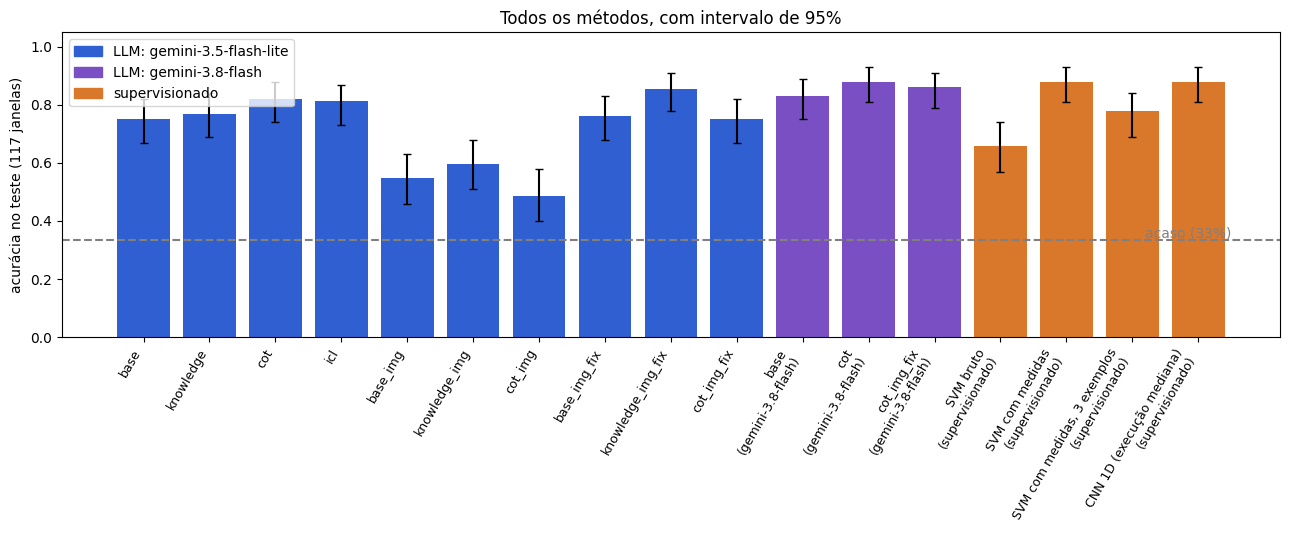

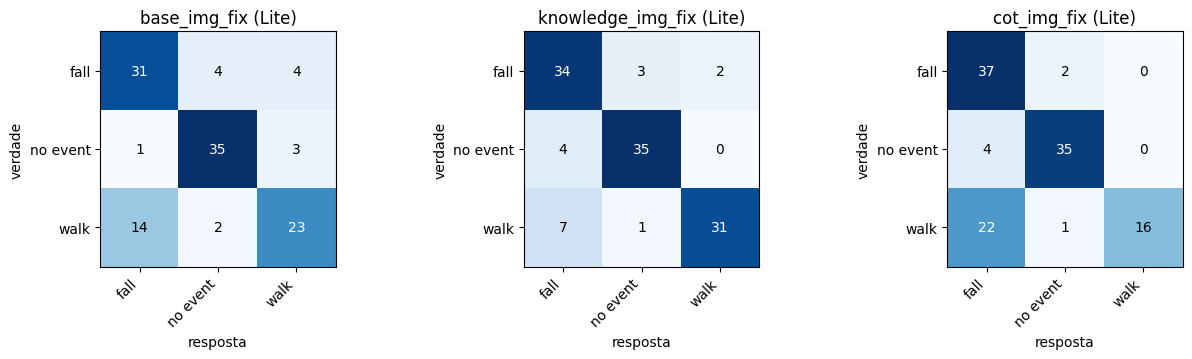

In [9]:
fig, ax = plt.subplots(figsize=(13, 5.5))
cores = {'LLM: ' + MODELO_LITE: '#2F5FD0', 'LLM: ' + MODELO_GRANDE: '#7A4FC4', 'supervisionado': '#D9772B'}
rot = [f'{r.metodo}\n({r.tipo.replace("LLM: ", "")})' if r.tipo != 'LLM: ' + MODELO_LITE else r.metodo for r in final.itertuples()]
y = final.acuracia.values
err = np.array([[a - float(r.ic95.split('–')[0]), float(r.ic95.split('–')[1]) - a] for a, r in zip(y, final.itertuples())]).T
ax.bar(range(len(final)), y, color=[cores.get(t, '#888') for t in final.tipo], yerr=err, capsize=3)
ax.axhline(1/3, ls='--', color='gray'); ax.text(len(final) - 0.5, 1/3 + 0.01, 'acaso (33%)', ha='right', color='gray')
ax.set_xticks(range(len(final))); ax.set_xticklabels(rot, rotation=60, ha='right', fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel('acurácia no teste (117 janelas)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in cores.items() if k in set(final.tipo)], loc='upper left')
ax.set_title('Todos os métodos, com intervalo de 95%')
plt.tight_layout(); fig.savefig(f'{OUT}/grafico_final.png', dpi=150); plt.show()

ests = [e for e in ['base_img_fix', 'knowledge_img_fix', 'cot_img_fix'] if ((res.modelo == MODELO_LITE) & (res.estrategia == e)).sum() == len(teste)]
if ests:
    fig, axes = plt.subplots(1, len(ests), figsize=(4.3 * len(ests), 3.7), squeeze=False)
    for ax, est in zip(axes[0], ests):
        r = res[(res.modelo == MODELO_LITE) & (res.estrategia == est)]
        cm = pd.crosstab(pd.Categorical(r.label, LABELS), pd.Categorical(r.pred, LABELS + ['breath', 'inválido']), dropna=False)
        cm = cm.loc[:, (cm.sum() > 0) | cm.columns.isin(LABELS)]
        ax.imshow(cm.values, cmap='Blues')
        ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels(cm.columns, rotation=45, ha='right')
        ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
        for (a, b), v in np.ndenumerate(cm.values):
            ax.text(b, a, v, ha='center', va='center', color='white' if v > cm.values.max() / 2 else 'black')
        ax.set_title(f'{est} (Lite)'); ax.set_xlabel('resposta'); ax.set_ylabel('verdade')
    plt.tight_layout(); plt.show()

## O que me mandar

1. A tabela da seção 2 e a linha da CNN (as 5 acurácias).
2. Os gráficos da seção 3 (escala automática × fixa).
3. A tabela final, o gráfico final e as matrizes da seção 7.

O gráfico final fica salvo em `nb03/grafico_final.png`, pronto para entrar nos slides.